# Linear and Logistic Regression

### Recap: the business problem

A debt collection agency wants to prioritise its outreach efforts. Chasing every
debtor equally wastes agent time on accounts unlikely to ever pay, while accounts
that *would* pay with the right follow-up may get missed. Predicting **who will
repay** and **how much** lets the agency focus effort where it actually matters.

### What EDA notebook already did

- Cleaned four raw tables (debtor profiles, accounts, payment transactions,
  contact history): handled structural nulls, malformed dates, duplicates,
  and outliers
- Engineered features: log-transformed skewed amounts, derived `age_at_default`,
  `city`, and date-based features
- Checked correlations, multicollinearity (VIF), and categorical associations
  (Cramér's V, Kruskal-Wallis)
- Derived five targets from the raw transaction and contact data:
  `repayment_probability`, `repayment_amount`, `time_to_repayment`,
  `response_probability`, `complaint_risk`
- Validated the train/val/test split: `debt_type` and `city` composition are
  stable across splits, but `age_at_default` and `repayment_amount` genuinely
  **drift** across the date-based splits
- Saved everything to `cleaned_dataset.pkl`, one row per account, features and
  targets already joined, split label already assigned

### What this notebook does

- Loads `cleaned_dataset.pkl` directly. No further cleaning or feature
  engineering, that's already done
- Two targets, two models:
  - **Linear regression** on `log_repayment_amount`
  - **Logistic regression** on `repayment_probability`
- For each target: scale (fit on train only), train several model variants
  side by side, evaluate train and test together, and interpret what the
  coefficients actually mean for the business
- Expect the train/test drift found in EDA notebook to show up here as a
  performance gap. Part of that gap is genuine target drift, not overfitting,
  worth keeping in mind when reading the metrics later in this notebook

## 1. Setup and Data Preparation
### 1.1 Imports and loading the data

In [1]:
#Core libraries
import pandas as pd     # DataFrame operations: loading, filtering, joining
import numpy as np      # numeric arrays and math (log/exp transforms, NaN handling)
import matplotlib.pyplot as plt  # base plotting
import seaborn as sns   # statistical plots (heatmaps, distribution plots) built on matplotlib
from scipy import stats # statistical tests (normality, group comparisons)

In [ ]:
# Load the feature matrix produced by EDA notebook. One row per account,
# features and all five targets already joined, split label already assigned
DATA_DIR = "../data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

print(f'Loaded: {master.shape[0]:,} rows, {master.shape[1]} columns')
print()
print('Split sizes:')
print(master['split'].value_counts())

Loaded: 13,945 rows, 31 columns

Split sizes:
split
train      8968
val        3115
test       1547
unknown     315
Name: count, dtype: int64


### 1.2 Removing accounts with no split assigned

In [3]:
##########################################
## Drop accounts with no split assigned ##
##########################################
# Drop the accounts with no valid split assignment (outside the defined
# date ranges), they can't be used for train/val/test comparison
master = master[master['split'] != 'unknown'].copy()

### 1.3 Encoding remaining categorical features

EDA notebook already ordinal-encoded `income_band` and `education_level`, since
those have a natural order. The remaining categorical columns (`debt_type`,
`status`, `city`, `gender`, `household_type`, `employment_status`,
`urban_category`, `country_of_origin`, `born_in_netherlands`) are nominal, no
inherent ordering, so they need **one-hot encoding** instead.

As with every other transform in this project, the encoder is **fit on train
only** and then applied to val and test, so no information about val/test
categories leaks into how the model is set up.

**NOTE**: We also drop the small `unknown` split here, accounts whose `default_date`
fell outside the defined train/val/test date ranges in EDA notebook, since
they can't be assigned to any comparison group.

In [ ]:
######################################################
## One-hot encode remaining nominal variables ##
######################################################
from sklearn.preprocessing import OneHotEncoder  # encodes nominal variables as dummy columns, fit on train only to avoid leakage

# Categorical columns still needing one-hot encoding (income_band and
# education_level were already ordinal-encoded in EDA notebook)
nominal_cols = ['debt_type', 'status', 'city', 'gender', 'household_type',
                'employment_status', 'urban_category', 'country_of_origin',
                'born_in_netherlands']
# Keep only the expected nominal columns that actually exist in master, so
# a missing/renamed column doesn't crash the encoder with a KeyError
nominal_cols = [c for c in nominal_cols if c in master.columns]

# NOTE: Fit the encoder using only the train rows, so val/test categories can
# never influence what the encoder learns.
#  astype(str) after fillna is needed because born_in_netherlands mixes Python bool (True/False) with
# the 'unknown' string, which breaks OneHotEncoder's internal sort
train_data = master[master['split'] == 'train']
#QUESTION: what does each of the input parameters in OneHotEncoder() mean?
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first') 
enc.fit(train_data[nominal_cols].fillna('unknown').astype(str))

# Apply the train-fitted encoder to the FULL table (train + val + test),
# filling missing categories the same way as when the encoder was fit
encoded = enc.transform(master[nominal_cols].fillna('unknown').astype(str))

# get_feature_names_out returns names like 'debt_type_Credit card', so the
# origin column and category are both visible in the resulting column names
encoded_cols = enc.get_feature_names_out(nominal_cols)

##########################################
## Attach the encoded columns to master ##
##########################################
# Wrap the encoded array back into a DataFrame, keeping master's original
# index so it lines up row-for-row for the concat below. list(...) on the
# columns converts from a numpy array to a plain list, which matches
# pandas' type stubs more cleanly (this is a type-checker-only concern, not something that affects runtime behaviour)
encoded_df = pd.DataFrame(encoded, columns=list(encoded_cols), index=master.index)

# Attach the new dummy columns onto master as additional columns (axis=1),
# the original nominal_cols stay in master too, unused as model input but
# kept for reference/readability
master = pd.concat([master, encoded_df], axis=1)

print(f'One-hot encoded {len(nominal_cols)} columns into {len(encoded_cols)} dummy columns')
print(f'Master shape after encoding: {master.shape}')


One-hot encoded 9 columns into 51 dummy columns
Master shape after encoding: (13630, 82)


In [5]:
# Quick sanity check: confirm the new dummy columns were attached correctly
master.head()

,account_id,debtor_id,split,log_original_amount,log_outstanding_balance,log_days_past_due,missed_payments,interest_rate,broken_arrangements,age_at_default,...,country_of_origin_Moroccan origin,country_of_origin_Other African origin,country_of_origin_Other Asian origin,country_of_origin_Other European origin,country_of_origin_Other origin,country_of_origin_Surinamese origin,country_of_origin_Turkish origin,country_of_origin_unknown,born_in_netherlands_True,born_in_netherlands_unknown
0,9ccc6dc7-8e96-4d43-92aa-49bb044bb08a,aa7588f7-dd4a-4a7f-bff8-54da2fab20a2,val,7.022289,6.739206,5.236442,7.0,17.05,1.0,60.416153,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,39866796-bbf7-43b7-a552-a5e4c1fb4354,aa7588f7-dd4a-4a7f-bff8-54da2fab20a2,train,6.009255,6.237406,6.762730,29.0,11.59,1.0,58.568104,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,eaba36a0-8e5e-4e17-a55d-b91d60c1e06f,77a6c22c-dc7f-4a6f-ae7f-fe7a1b3305f5,val,5.573218,4.815836,5.342334,6.0,0.00,2.0,51.874059,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,eedc8d1a-6c22-441d-ab43-75c83467b96a,77a6c22c-dc7f-4a6f-ae7f-fe7a1b3305f5,train,6.945321,7.006722,5.805135,11.0,14.62,4.0,50.384668,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,38396424-7631-4b1c-92ce-af0ed2ad320e,4be5cd8c-959c-4765-92ac-e297f192aaf2,train,7.821663,7.091542,4.779123,2.0,9.34,0.0,72.914442,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### 1.4 Defining the feature set

In [ ]:
############################
## 1.4 Define the feature set ##
############################
# Numeric features engineered in EDA notebook (log-transformed amounts, dates, encoded ordinal categoricals, and data-quality flags)
numeric_features = ['log_original_amount', 'log_outstanding_balance', 'log_days_past_due',
                    'missed_payments', 'interest_rate', 'broken_arrangements',
                    'age_at_default', 'default_month', 'default_year',
                    'income_band_encoded', 'education_level_encoded',
                    'balance_capped', 'default_date_imputed']

# One-hot encoded dummy columns created in the previous cell
dummy_features = list(encoded_cols)

# The full feature list used to train every model in this notebook
feature_cols = numeric_features + dummy_features
print(f'Total features: {len(feature_cols)}')

Total features: 64


### 1.5 Checking for missing values

In [13]:
##################################################
## Check for missing values before modelling    ##
##################################################
# MinMaxScaler and sklearn's regression models cannot handle NaN, so any
# missing values left in the feature columns need to be found and dealt
# with now, before fitting anything
null_counts = master[feature_cols].isna().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)

if len(null_counts) > 0:
    print('Columns with remaining missing values:')
    print(null_counts)
else:
    print('No missing values found in the feature columns.')

No missing values found in the feature columns.


#### Why do NaNs still exist after EDA notebook's feature engineering?

EDA notebook only imputed the specific columns its own EDA flagged as MNAR:
`income_band`, `employment_status`, `education_level`, and `age_at_default`.
`days_past_due` and `broken_arrangements` were never on that list, they're raw
account-level columns, and `log1p(NaN)` is still `NaN`, the log transform
reshapes existing values, it doesn't fix missingness.

**What went wrong:** Ideally, a complete null audit (checking every column in the final feature
matrix, not just the ones EDA happened to surface) would have run as part of
EDA notebook, right before the pickle was saved, and any needed imputation or
drop decision would have been made there, consistent with the leakage-avoidance
pattern already established in that notebook. We handle it here instead,
since EDA notebook is already finalised, but it's worth recognising this as a
gap between what got expicitly checked and what the full feature set here
actually needs, not a new problem introduced by this tutorial.

In [14]:
##################################################
## Investigate before deciding how to handle it ##
##################################################
# Check whether the two null columns overlap (same rows, or different rows)
null_log_days = master['log_days_past_due'].isna()
null_broken   = master['broken_arrangements'].isna()
print(f'Rows null in log_days_past_due only: {(null_log_days & ~null_broken).sum()}')
print(f'Rows null in broken_arrangements only: {(~null_log_days & null_broken).sum()}')
print(f'Rows null in both: {(null_log_days & null_broken).sum()}')
print()

# Check whether the missing rows are concentrated in one split, dropping
# disproportionately from test would be worse than dropping from train
any_null = null_log_days | null_broken
print('Rows with any missing feature, by split:')
print(master.loc[any_null, 'split'].value_counts())
print()
print('As a percentage of each split:')
print((master.loc[any_null, 'split'].value_counts() / master['split'].value_counts() * 100).round(2))

Rows null in log_days_past_due only: 0
Rows null in broken_arrangements only: 0
Rows null in both: 0

Rows with any missing feature, by split:
Series([], Name: count, dtype: int64)

As a percentage of each split:
split
test    NaN
train   NaN
val     NaN
Name: count, dtype: float64


#### Handling the missing values

The investigation above shows `log_days_past_due` has 68 NaNs and
`broken_arrangements` has 41, with **no overlap** between the two (a row is
never missing both), and the affected rows are a small, roughly even share of
every split (0.65-0.83%), not concentrated in test.

Since this notebook's scope is modelling, not further feature engineering, and
the missing rows are small and evenly spread, we drop them rather than
introduce new imputation logic this late in the pipeline. This is safe here
specifically because the investigation confirmed it won't disproportionately
shrink any one split or bias the test set, that check should always come
before deciding to drop, not after.

In [15]:
##########################################
## Drop rows with missing feature values ##
##########################################
# Both null columns are small (68 and 41 rows, no overlap) and spread
# evenly across splits (0.65-0.83%), so a simple drop is safe here: it
# won't disproportionately shrink any one split or bias evaluation
rows_before = len(master)
master = master.dropna(subset=feature_cols).copy()
rows_dropped = rows_before - len(master)

print(f'Dropped {rows_dropped} rows with missing feature values ({rows_dropped/rows_before*100:.2f}% of data)')
print()
print('Split sizes after dropping:')
print(master['split'].value_counts())

Dropped 0 rows with missing feature values (0.00% of data)

Split sizes after dropping:
split
train    8894
val      3090
test     1537
Name: count, dtype: int64


## 2. Linear Regression for prediction repayment amount

### 2.1 Scaling the features and train/test split

**Theory: why scale, and why StandardScaler specifically**

- Linear and logistic regression fit coefficients by minimising a loss function via gradient-based optimisation. Features on very different scales (e.g. `interest_rate` around 0-20 vs `outstanding_balance` in the thousands) distort this: the optimiser effectively treats larger-magnitude features as more important, regardless of their actual predictive value.
- Regularised variants (Ridge, Lasso) are even more scale-sensitive, since the penalty term is applied directly to the coefficients. An unscaled feature with a naturally small coefficient (because its values are large) would be penalised differently than the same feature scaled, purely as an artifact of units, not genuine importance.
- **StandardScaler** transforms each feature to have mean 0 and standard deviation 1:

$$x_{scaled} = \frac{x - \mu}{\sigma}$$

  where $\mu$ and $\sigma$ are the feature's mean and standard deviation, **computed from the training set only**.

- As with every other transform in this project: **fit on train, apply to train and test**. Fitting on test would leak its distribution into the scaling itself, before the model has even been trained.

**Other scalers worth knowing about:**

| Scaler | How it works | When to prefer it |
|---|---|---|
| **StandardScaler** | Rescales to mean 0, std 1 | Default choice for linear/logistic regression; assumes roughly Gaussian-ish features, though it still works reasonably without that |
| **MinMaxScaler** | Rescales to a fixed range, usually [0, 1], using $(x - min) / (max - min)$ | Useful when you need bounded output (e.g. neural network inputs with sigmoid/tanh activations); sensitive to outliers, since a single extreme value stretches the whole range |
| **RobustScaler** | Centres on the median and scales by the interquartile range (IQR) instead of mean/std | Better when the feature has heavy outliers, exactly the kind of right-skewed, outlier-prone columns flagged back in EDA notebook Section 5.2, since median/IQR aren't pulled around by extreme values the way mean/std are |
| **Normalizer** | Scales each *row* (not column) to unit norm | Different purpose entirely, used when the direction of a feature vector matters more than its magnitude (e.g. text/TF-IDF vectors); rarely relevant for tabular business data like this |
| **MaxAbsScaler** | Divides by the maximum absolute value, preserving sparsity | Useful for sparse data (lots of zeros, e.g. one-hot encoded columns) where centering would destroy the sparsity structure |

We use StandardScaler here since it's the standard choice for linear/logistic regression and matches the rest of this tutorial's evaluation approach, but it's worth trying `RobustScaler` as an exercise given how right-skewed several of these features were shown to be in EDA notebook, even after the log transform.

Documentation: [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)  
Documentation: [sklearn preprocessing user guide](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling)

In [ ]:
##############################################################
## Train-test split (using EDA notebook's pre-assigned split) ##
##############################################################
# We do NOT call train_test_split here. EDA notebook already assigned each
# account to train/val/test based on its default date, so we just filter
# master by that existing 'split' column. We only use train and test in
# this tutorial, val is introduced in the KNN tutorial once hyperparameter
# tuning against a validation set matters.
df_train = master[master['split'] == 'train']
df_test  = master[master['split'] == 'test']

# As standard practice, rename into X_train, X_test, y_train, y_test
X_train = df_train[feature_cols]
y_train = df_train['log_repayment_amount']
X_test  = df_test[feature_cols]
y_test  = df_test['log_repayment_amount']

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')

##########################################################
## Scaling the feature variables using StandardScaler   ##
##########################################################
from sklearn.preprocessing import StandardScaler  # standardises features to mean 0, std 1, fit on train only to avoid leakage

# Define the StandardScaler instance
scaler = StandardScaler()
# Fit the scaler using ONLY the training data
scaler.fit(X_train)
# Scale X_train using the scaler fitted on the training data
X_train_scaled = scaler.transform(X_train)
# Wrap the scaled array back into a DataFrame with the original column names
df_X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)

# IMPORTANT: to scale X_test, use the SAME scaler fitted on the training data. 
# The scaled X_test is only ever used for model assessment.
# NOTE: do not fit the scaler on the test dataset. 
# Doing so would leak information from the test dataset into the model and bias the results.
# The test dataset is sacred, none of its properties should influence any step that happens before evaluation.
X_test_scaled = scaler.transform(X_test)

# Wrap the scaled array back into a DataFrame with the original column names
df_X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test.index)

X_train: (8894, 64), X_test: (1537, 64)


### 2.2 A note on linear regression assumptions

Classical linear regression theory (linearity, homoscedasticity, normality of
residuals) matters most when the goal is **inference**, trusting the
statistical significance of coefficients, or building exact confidence
intervals around them. That's the concern we saw in **Business Statistics**.

Here, the goal is **prediction**: how well does the model generalise to
unseen accounts, measured by RMSE, MAE, and R² on the test set. Coefficients
are read for *business insight* (which features move the prediction and by
how much), not to make formal statistical claims about the population. This
matters even more once Ridge and Lasso enter the picture, regularised
coefficients are deliberately biased by design, so classical assumption
checks built around unbiased OLS estimators don't cleanly apply to them
anyway.

For that reason, we won't run formal residual diagnostics here, worth
knowing these assumptions exist and what they're for, but not the focus of
an applied ML workflow like this one.

### 2.3 Model training

We train three linear regression models on `log_repayment_amount`:

- **Model 1**: using all features
- **Model 2**: excluding `missed_payments` and `log_days_past_due`, the two
  features Tutorial 0's VIF check flagged above the 5.0 warning threshold
- **Model 3**: Ridge regression (L2 regularisation) using all features,
  `alpha=1` (the default). We won't tune this hyperparameter manually in this
  tutorial, hyperparameter tuning against a validation set is introduced in
  the KNN tutorial

In [ ]:
######################################################
## Fitting three different linear regression models ##
######################################################
from sklearn.linear_model import LinearRegression, Ridge  # LinearRegression: baseline OLS; Ridge: L2-regularised variant

# Reduced feature set, excluding the two VIF-flagged features (EDA notebook
# found missed_payments and log_days_past_due both above VIF=5)
reduced_features = [c for c in feature_cols if c not in ('missed_payments', 'log_days_past_due')]

# Model 1: all features, no regularization
regressor1 = LinearRegression().fit(df_X_train_scaled, y_train)
print('-------------------------------------------------------------------------')
print('Model 1: linear regression using all features')
print('R-2 on training data: %.3f' % regressor1.score(df_X_train_scaled, y_train))
print('-------------------------------------------------------------------------')

# Model 2: reduced feature set, excluding the VIF-flagged features
regressor2 = LinearRegression().fit(df_X_train_scaled[reduced_features], y_train)
print('-------------------------------------------------------------------------')
print('Model 2: linear regression excluding missed_payments and log_days_past_due')
print('R-2 on training data: %.3f' % regressor2.score(df_X_train_scaled[reduced_features], y_train))
print('-------------------------------------------------------------------------')

# Model 3: Ridge regression, all features, alpha=1 (default, not tuned)
regressor3 = Ridge(alpha=1).fit(df_X_train_scaled, y_train)
print('-------------------------------------------------------------------------')
print('Model 3: Ridge regression using all features (alpha=1)')
print('R-2 on training data: %.3f' % regressor3.score(df_X_train_scaled, y_train))
print('-------------------------------------------------------------------------')

-------------------------------------------------------------------------
Model 1: linear regression using all features
R-2 on training data: 0.255
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 2: linear regression excluding missed_payments and log_days_past_due
R-2 on training data: 0.164
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 3: Ridge regression using all features (alpha=1)
R-2 on training data: 0.255
-------------------------------------------------------------------------


### 2.4 What we observe from training

- **R² here is measured on the log scale** (`log_repayment_amount`), since that's what each model was actually fit on, this print is a quick sanity check right after fitting, not the final reported metric
- **Model 1 (all features): R² = 0.255** and **Model 3 (Ridge, alpha=1): R² = 0.255**, identical. At `alpha=1`, Ridge's penalty is too gentle to meaningfully shrink any coefficients given only moderate multicollinearity (VIF ~6, not ~60+), so it behaves almost exactly like plain OLS here
- **Model 2 (reduced features): R² = 0.164**, a substantial drop from 0.255. Removing `missed_payments` and `log_days_past_due` costs roughly a third of the explained variance
- This is worth sitting with: those two features were flagged for *moderate* multicollinearity (VIF just above 5, well below the 10.0 "problematic" line), not severity that would usually justify dropping them outright. The R² drop confirms they were carrying real predictive signal, not redundant noise, consistent with EDA notebook's finding that `log_days_past_due` and `missed_payments` were the two continuous features most correlated with the preview repayment target
- Takeaway: a VIF flag alone doesn't mean a feature should be dropped, multicollinearity is a warning to investigate, not an automatic removal rule, and this result is direct evidence of that

### 2.5 Model assessment

- We predict on both train and test for all three models
- All metrics are reported on the **raw EUR scale**, not the log scale the models were trained on
- Predictions come out as `log_repayment_amount`, so we apply `np.expm1()` (the inverse of `log1p()` from EDA notebook) to both predictions and true values before computing anything
- **MAE, MSE, RMSE, and R² in EUR are what the business actually cares about, not log-EUR**
- Train and test metrics are always reported together, side by side, so a gap between them is visible rather than hidden
- Given what EDA notebook found, expect part of any train-test gap here to reflect genuine **target drift** (Section 9's KS test found `repayment_amount` shifting significantly across splits), not purely overfitting

In [ ]:
##########################################################
## Model assessment: predictions and metrics (EUR scale) ##
##########################################################
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # regression metrics

models = {
    'Model 1 (all features)': (regressor1, df_X_train_scaled, df_X_test_scaled),
    'Model 2 (reduced features)': (regressor2, df_X_train_scaled[reduced_features], df_X_test_scaled[reduced_features]),
    'Model 3 (Ridge, alpha=1)': (regressor3, df_X_train_scaled, df_X_test_scaled),
}

for name, (model, X_tr, X_te) in models.items():
    # Predict on the log scale, then invert back to EUR with expm1
    # (the exact inverse of the log1p() applied in EDA notebook)
    y_train_pred_eur = np.expm1(model.predict(X_tr))
    y_test_pred_eur  = np.expm1(model.predict(X_te))
    y_train_eur = np.expm1(y_train)
    y_test_eur  = np.expm1(y_test)

    mae_train  = mean_absolute_error(y_train_eur, y_train_pred_eur)
    mae_test   = mean_absolute_error(y_test_eur, y_test_pred_eur)
    mse_train  = mean_squared_error(y_train_eur, y_train_pred_eur)
    mse_test   = mean_squared_error(y_test_eur, y_test_pred_eur)
    rmse_train = np.sqrt(mse_train)
    rmse_test  = np.sqrt(mse_test)
    r2_train   = r2_score(y_train_eur, y_train_pred_eur)
    r2_test    = r2_score(y_test_eur, y_test_pred_eur)

    print('-------------------------------------------------------------------------')
    print(name)
    print('MAE  - train: %.2f, test: %.2f' % (mae_train, mae_test))
    print('MSE  - train: %.2f, test: %.2f' % (mse_train, mse_test))
    print('RMSE - train: %.2f, test: %.2f' % (rmse_train, rmse_test))
    print('R-2  - train: %.3f, test: %.3f' % (r2_train, r2_test))
    print('-------------------------------------------------------------------------')

-------------------------------------------------------------------------
Model 1 (all features)
MAE  -> train: 22.39, test: 69.56
MSE  -> train: 5036.51, test: 23716.46
RMSE -> train: 70.97, test: 154.00
R-2  -> train: -0.031, test: -0.178
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 2 (reduced features)
MAE  -> train: 23.11, test: 71.11
MSE  -> train: 5217.27, test: 24353.51
RMSE -> train: 72.23, test: 156.06
R-2  -> train: -0.068, test: -0.210
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 3 (Ridge, alpha=1)
MAE  -> train: 22.39, test: 69.56
MSE  -> train: 5037.35, test: 23723.38
RMSE -> train: 70.97, test: 154.02
R-2  -> train: -0.031, test: -0.179
-------------------------------------------------------------------------


### 2.6 What we observe: EUR-scale performance is far worse, even negative

- **R² is negative for all three models, on both train and test.** A negative R² means the model's EUR predictions are *worse* than the simplest possible baseline: just predicting the average `repayment_amount` for every single account
- **This happens even on train**, so this isn't primarily an overfitting or drift story here, the model already fails to beat a flat-mean baseline before test data enters the picture at all
- **The log-scale fit (R²=0.255) doesn't survive the trip back to EUR:**
  - `log_repayment_amount` was built over **every account, not payers only**, most debtors pay nothing, so the target is a huge spike at zero plus a right-skewed tail of actual payments
  - `expm1()` is a **convex, nonlinear** transform: minimising squared error in log-space does not minimise squared error in EUR-space, they're mathematically different objectives
  - R² is dominated by the largest squared errors, a handful of large repayment amounts, mispredicted only slightly in log-space, are enough to drag R² negative, even while MAE (22-71 EUR) looks comparatively reasonable
- **Model 2 (reduced features) is worst across every metric**, consistent with its weaker log-scale fit from before
- **Model 1 and Model 3 (Ridge) remain nearly identical**, same explanation as before: `alpha=1` isn't strong enough to meaningfully change the fit

**QUESTION:** MAE looks fairly reasonable here (22-71 EUR), while R² is negative for the exact same predictions. How can one metric suggest the model is "not terrible" while another suggests it's worse than predicting the average? What does this tell you about relying on a single metric to judge a model?

**QUESTION:** The model was trained to minimise error in log-space, but the business cares about error in EUR. Given what you now know about how `expm1()` behaves, would optimising directly for EUR-scale error (rather than log-scale) have produced a better EUR-scale result, or does the underlying problem, one linear model trying to represent both "pays nothing" and "pays a lot", remain regardless of which scale you optimise on?

**QUESTION:** Given that most debtors pay nothing at all, what would happen to these metrics if you evaluated the model only on payers (`repayment_amount > 0`), rather than on every account? Would you expect R² to improve, worsen, or is it not obvious without checking?

## 3. Logistic Regression to predict if a debtor will pay within 90 days
### 3.1 Overview

We now switch targets, from `log_repayment_amount` (continuous, how much) to
`repayment_probability` (binary, will they pay at all within 90 days).

- Same feature set as the linear regression section (`feature_cols`), and the
  same `df_X_train_scaled`/`df_X_test_scaled` scaled features, scaling only
  depends on the features, not the target, so it doesn't need to be refit.
- Only `y_train`/`y_test` change, they'll now come from `repayment_probability`
  instead of `log_repayment_amount`.
- Recall from EDA notebook Section 8.1: this target is **imbalanced**, most
  debtors don't repay within 90 days. That imbalance is the central design
  consideration for this whole section, and drives most of what's different
  here compared to linear regression: `class_weight='balanced'`, and
  evaluating with F1/ROC-AUC/precision/recall instead of accuracy.


#### A note on ordering: why we did linear regression first, even though probability comes first in practice

For the business problem, the natural order is the opposite of how this tutorial is structured:

- **In practice**, the agency's first question is *"will this debtor pay at
  all?"* (`repayment_probability`), only once that's answered does *"how
  much will they pay?"* (`repayment_amount`) become relevant. There's no
  point estimating a repayment amount for an account the agency doesn't
  expect to collect from.
- **In this tutorial**, we covered linear regression (`repayment_amount`)
  first, and logistic regression (`repayment_probability`) second, purely
  for pedagogical reasons, to introduce continuous-target and binary-target
  modelling as two separate techniques in sequence.

This ordering mismatch is worth sitting with rather than glossing over,
because it directly explains the negative R² result from Part 1. We trained
a single linear model to predict `repayment_amount` across **every** account,
payers and non-payers together, effectively asking one model to answer both
business questions at once. The logistic regression in this section is the
piece that should have come first: `repayment_probability` is the actual
gating decision the agency needs. A more realistic pipeline would use this
section's model as **Stage 1** (who's likely to pay), and only apply Part 1's
regression as **Stage 2**, conditionally, to the accounts Stage 1 flags as
likely payers. 

We don't build that full two-stage pipeline in this tutorial,
but *keep it in mind*: the negative R² wasn't just a modelling mistake, it was
a consequence of skipping the business's own natural first step.

### 3.2 Extracting the classification target

Same features, same scaling, only the target changes, from `log_repayment_amount` to `repayment_probability`.

In [25]:
##########################################################
##          Extract the classification target           ##
##########################################################
# X_train/X_test and their scaled versions don't change, scaling only
# depends on the features, not the target. Only y_train/y_test are new here
y_train_clf = df_train['repayment_probability']
y_test_clf  = df_test['repayment_probability']

print(f'y_train_clf: {y_train_clf.shape}, y_test_clf: {y_test_clf.shape}')
print()
print('Class balance (train):')
print(y_train_clf.value_counts(normalize=True).round(3) * 100)

y_train_clf: (8894,), y_test_clf: (1537,)

Class balance (train):
repayment_probability
0    74.6
1    25.4
Name: proportion, dtype: float64


### 3.3 Handling class imbalance: `class_weight='balanced'`

- In our train split, **74.6% of accounts don't repay within 90 days, only 25.4% do**, roughly a 3:1 imbalance
- A naive classifier predicting class 0 for every account would score ~74.6% accuracy while catching zero actual payers, the accuracy paradox covered in EDA notebook
- **`class_weight='balanced'`** addresses this directly in the loss function itself, no changes to the data, no oversampling. Each class gets a weight inversely proportional to its frequency:

$$w_c = \frac{n_{samples}}{n_{classes} \times n_{samples,\ c}}$$

- In practice, this means every misclassified minority-class (paying) account contributes more to the loss than a misclassified majority-class (non-paying) account, pushing the model to actually pay attention to the minority class rather than ignoring it
- This is the method we're using consistently across every classification tutorial (per the note back in EDA notebook Section 8.1), other resampling techniques like SMOTE exist and are worth knowing about, but aren't what we use here
- Because of this, **accuracy is not a meaningful metric on its own** for this target, we'll use F1, precision, recall, and ROC-AUC instead, and look at the confusion matrix directly

Documentation: [sklearn class_weight](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)

### 3.4 Feature engineering for logistic regression

- We use the same features and scaling as the linear regression section
  (`feature_cols`, `df_X_train_scaled`/`df_X_test_scaled`), scaling doesn't
  depend on the target, so nothing needs to be refit

**QUESTION:** `gender` is available as a set of one-hot encoded features in
this dataset. Should it be used as a predictor for a business decision like
prioritising debt collection outreach? Consider: does including it likely
improve predictive performance? Even if it does, is that improvement worth
the fairness risk of a collection decision being influenced by gender? Is
there a difference between a feature *correlating* with the outcome and a
feature being *appropriate* to act on?

For the models below, we exclude `gender` from the feature set by default.
Try adding it back in once you've trained the models, and compare the
results, does performance change enough to justify revisiting your answer
above?

In [26]:
##########################################################
## Feature set excluding gender (sensitive attribute)   ##
##########################################################
# Excluded here by default. See the QUESTION above: add gender_cols back
# into feature_cols_no_gender yourself to test whether it changes performance
gender_cols = [c for c in feature_cols if c.startswith('gender_')]
feature_cols_no_gender = [c for c in feature_cols if c not in gender_cols]

print(f'Excluded {len(gender_cols)} gender-related columns: {gender_cols}')
print(f'Features used for logistic regression: {len(feature_cols_no_gender)}')

Excluded 4 gender-related columns: ['gender_Male', 'gender_Non-binary / other', 'gender_Not disclosed', 'gender_unknown']
Features used for logistic regression: 60


### 3.5 Model training

We train two logistic regression models on `repayment_probability`, both
using `class_weight='balanced'`, neither uses `gender` as a feature (see the
QUESTION above):

- **Model 1**: no regularisation
- **Model 2**: L2-regularised (`C=0.2`), a stronger penalty than the
  library's default (`C=1.0`), read the [LogisticRegression
  documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
  what is `C`, and how does it relate to the regularisation strength?

In [27]:
#############################################
## Fitting the logistic regression models  ##
#############################################
from sklearn.linear_model import LogisticRegression  # binary classifier; class_weight='balanced' compensates for the 74.6/25.4 class imbalance

# Model 1: no regularisation, class_weight='balanced'
log_regressor1 = LogisticRegression(penalty=None, class_weight='balanced').fit(
    df_X_train_scaled[feature_cols_no_gender], y_train_clf)
print('-------------------------------------------------------------------------')
print('Model 1: logistic regression, no regularisation, class_weight=balanced')
print('Mean accuracy on training data: %.3f' % log_regressor1.score(df_X_train_scaled[feature_cols_no_gender], y_train_clf))
print('-------------------------------------------------------------------------')

# Model 2: L2-regularised, class_weight='balanced'. C is the inverse of
# regularisation strength, smaller C means stronger regularisation
log_regressor2 = LogisticRegression(penalty='l2', C=0.2, class_weight='balanced').fit(
    df_X_train_scaled[feature_cols_no_gender], y_train_clf)
print('-------------------------------------------------------------------------')
print('Model 2: logistic regression, L2-regularised (C=0.2), class_weight=balanced')
print('Mean accuracy on training data: %.3f' % log_regressor2.score(df_X_train_scaled[feature_cols_no_gender], y_train_clf))
print('-------------------------------------------------------------------------')

-------------------------------------------------------------------------
Model 1: logistic regression, no regularisation, class_weight=balanced
Mean accuracy on training data: 0.752
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 2: logistic regression, L2-regularised (C=0.2), class_weight=balanced
Mean accuracy on training data: 0.750
-------------------------------------------------------------------------


### 3.6 Model assessment

We predict on both train and test for both models, and report F1, precision,
recall, and ROC-AUC as `train: %.3f, test: %.3f` pairs, the same convention
used throughout this project. Confusion matrices are shown separately, for
train and test, since they show raw counts rather than a single number and
don't compress as cleanly into that pairing.

ROC-AUC needs predicted probabilities, not just the 0/1 class prediction, so
we use `.predict_proba()` for that metric specifically.

-------------------------------------------------------------------------
Model 1 (no regularisation)
F1        - train: 0.597, test: 0.679
Precision - train: 0.508, test: 0.589
Recall    - train: 0.723, test: 0.802
ROC-AUC   - train: 0.823, test: 0.744
-------------------------------------------------------------------------
-------------------------------------------------------------------------
Model 2 (L2, C=0.2)
F1        - train: 0.594, test: 0.681
Precision - train: 0.506, test: 0.589
Recall    - train: 0.721, test: 0.807
ROC-AUC   - train: 0.822, test: 0.744
-------------------------------------------------------------------------


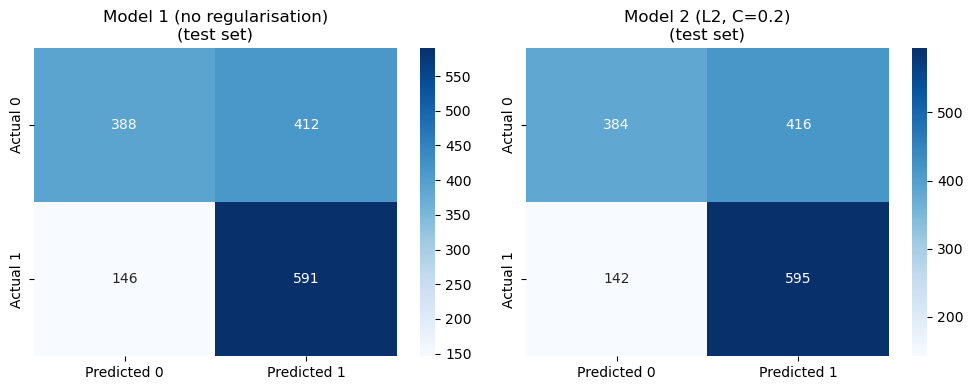

In [28]:
##########################################################
## Model assessment: F1, precision, recall, ROC-AUC     ##
##########################################################
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)  # classification metrics + confusion matrix

# Both models to evaluate, keyed by a readable name for the printed output
log_models = {
    'Model 1 (no regularisation)': log_regressor1,
    'Model 2 (L2, C=0.2)': log_regressor2,
}

for name, model in log_models.items():
    X_tr = df_X_train_scaled[feature_cols_no_gender]  # train features, gender excluded
    X_te = df_X_test_scaled[feature_cols_no_gender]    # test features, gender excluded

    y_train_pred = model.predict(X_tr)  # class predictions (0/1) on train, default 0.5 threshold
    y_test_pred  = model.predict(X_te)  # class predictions (0/1) on test, default 0.5 threshold

    y_train_proba = model.predict_proba(X_tr)[:, 1]  # P(class=1) on train, needed for ROC-AUC
    y_test_proba  = model.predict_proba(X_te)[:, 1]  # P(class=1) on test, needed for ROC-AUC

    f1_train   = f1_score(y_train_clf, y_train_pred)          # F1 on train
    f1_test    = f1_score(y_test_clf, y_test_pred)             # F1 on test
    prec_train = precision_score(y_train_clf, y_train_pred)   # precision on train
    prec_test  = precision_score(y_test_clf, y_test_pred)      # precision on test
    rec_train  = recall_score(y_train_clf, y_train_pred)       # recall on train
    rec_test   = recall_score(y_test_clf, y_test_pred)          # recall on test
    auc_train  = roc_auc_score(y_train_clf, y_train_proba)      # ROC-AUC on train, uses probabilities not class labels
    auc_test   = roc_auc_score(y_test_clf, y_test_proba)        # ROC-AUC on test, uses probabilities not class labels

    print('-------------------------------------------------------------------------')
    print(name)
    print('F1        - train: %.3f, test: %.3f' % (f1_train, f1_test))
    print('Precision - train: %.3f, test: %.3f' % (prec_train, prec_test))
    print('Recall    - train: %.3f, test: %.3f' % (rec_train, rec_test))
    print('ROC-AUC   - train: %.3f, test: %.3f' % (auc_train, auc_test))
    print('-------------------------------------------------------------------------')

##########################################################
## Confusion matrices (test set only, train omitted for ##
## space, train can be inspected the same way if needed)##
##########################################################
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # one subplot per model, side by side

for ax, (name, model) in zip(axes, log_models.items()):
    X_te = df_X_test_scaled[feature_cols_no_gender]  # test features, gender excluded
    y_test_pred = model.predict(X_te)  # class predictions (0/1) on test

    cm = confusion_matrix(y_test_clf, y_test_pred)  # rows = actual, columns = predicted; diagonal = correct

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
               xticklabels=['Predicted 0', 'Predicted 1'],
               yticklabels=['Actual 0', 'Actual 1'])
    ax.set_title(f'{name}\n(test set)')

plt.tight_layout()
plt.show()

### 3.7 What we observe

- Both models perform almost identically, L2 regularisation at `C=0.2` barely moves any metric, similar to Ridge in the linear regression section
- F1, precision, and recall are all *better* on test than train (e.g. recall: 0.723 → 0.802), the opposite of typical overfitting
- ROC-AUC moves the other way: 0.823 (train) → 0.744 (test), a real drop
- Threshold-dependent metrics (F1/precision/recall) are sensitive to each split's class balance; ROC-AUC isn't, worth checking whether a shift in `repayment_probability`'s class balance across splits explains the disagreement

**QUESTIONS:**
- Check the actual class balance of `repayment_probability` in test vs train. Does that difference explain why F1/precision/recall improve on test while ROC-AUC drops?
- Which of the two models would you deploy, and why, given the metrics above?
- L2 regularisation at `C=0.2` barely changed performance here. Try a much smaller `C` (stronger penalty), what happens to the coefficients?
- Retrain both models with `gender` added back into the feature set (undo the exclusion in `feature_cols_no_gender`), and compare F1, precision, recall, and ROC-AUC against the results above. Does performance change enough to justify including it? If it does improve performance, does that change your answer to the earlier question about whether `gender` *should* be used, or are predictive lift and appropriateness genuinely separate questions?